# TRABAJO Parte 2: AIA_2025-2026

# Transfer Learning con CNNs - Dataset: Flowers

La idea de este trabajo es familiarizarnos con dos situaciones muy habituales en la actividad real de un "Machine Learning Engineer":

1.   En primer lugar, con una de las técnicas más potentes asociadas con las redes neuronales: el **Transfer Learning**. Dado que las redes neuronales, para resolver un problema, capturan en su estructura de capas y pesos una representación jerárquica del problema.
Entonces..., ¿por que no aprovechar ese conocimiento obtenido, para resolver otro problema diferente?

2.  En segundo lugar, con la **busqueda de información sobre conceptos nuevos**. En este caso, los dos primeros modelos a implementar los hemos trabajado en clase. No así el Transfer Learning, y por tanto, debereis buscar vosotros mismos como hacer lo que se pide para el Modelo 3. Consultar en blogs, web y tutoriales es algo común en el día a día de alguien que quiere profundizar en el ML y, para ello, existen infinidad de fuentes. A modo de ejemplo, una fuente para profundizar en el Transfer Learning con redes convolucionales es: https://www.learndatasci.com/tutorials/hands-on-transfer-learning-keras/

En este trabajo vamos intentar resolver un problema de clasificación sobre un dataset propuesto por Tensorflow en 2019 conocido como "flowers". Este conjunto está formado por 3670 imágenes de flores pertenecientes a 5 clases diferentes. Para ello implementaremos 3 modelos:

*   Modelo 1: implementación de una CNN básica.
*   Modelo 2: es una evolución del modelo anterior, aplicando técnicas que reduzcan el overfitting.
*   Modelo 3: rompemos la barrera de tener que seguir complicando nuestro modelo y se pide aplicar transfer learning utilizando un pre-trained model.





# a) Carga de datos

In [1]:
import tensorflow as tf
from tensorflow import keras

import numpy as np
import pandas as pd

import pathlib
import os
import glob
import shutil
tf.__version__

C:\Users\Sara\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:102: RequestsDependencyWarning: urllib3 (1.26.20) or chardet (5.2.0)/charset_normalizer (2.0.12) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({})/charset_normalizer ({}) doesn't match a supported "


'2.21.0'

In [2]:
import warnings
warnings.filterwarnings('ignore')

Descargamos el dataset que pone a nuestra disposición Tensorflow.

In [7]:
_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

zip_file = tf.keras.utils.get_file(origin=_URL,
                                   fname="flower_photos.tgz",
                                   extract=True,
                                   )

base_dir = os.path.join(os.path.dirname(zip_file), 'flower_photos')

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 26s 0us/step


Tras completar la descarga, debemos tener la siguiente estructura de directorios:  

<pre style="font-size: 10.0pt; font-family: Arial; line-height: 2; letter-spacing: 1.0pt;" >
<b>~/.keras/datasets/flower_photos_extracted/flower_photos</b>
|__ <b>daisy</b>
|__ <b>dandelion</b>
|__ <b>roses</b>
|__ <b>sunflowers</b>
|__ <b>tulips</b>
</pre>

Desgraciadamente, para este dataset, Tensorflow no nos proporciona la estructura de directorios necesaria de train y de validación. Por lo que debemos proceder del siguiente modo:

* Crear una carpeta `train` y de `val`, cada una de ellas debe contener a su vez, cinco subdirectorios: uno para cada clase de flor.
* Moveremos las imágenes de las carpetas originales a estas nuevas carpetas. De modo que el 80% de las imágenes vayan al conjunto de train y el 20% restante al de validación.
* La estructura final de directorios debe ser la siguiente:

<pre style="font-size: 10.0pt; font-family: Arial; line-height: 2; letter-spacing: 1.0pt;" >
<b>~/.keras/datasets/flower_photos_extracted/flower_photos</b>
|__ <b>train</b>
    |______ <b>daisy</b>: [12.jpg, 28.jpg, 31.jpg ....]
    |______ <b>dandelion</b>: [41.jpg, 22.jpg, 35.jpg ....]
    |______ <b>roses</b>: [121.jpg, 92.jpg, 38.jpg ....]
    |______ <b>sunflowers</b>: [93.jpg, 23.jpg, 83.jpg ....]
    |______ <b>tulips</b>: [109.jpg, 267.jpg, 93.jpg ....]
 |__ <b>val</b>
    |______ <b>daisy</b>: [507.jpg, 508.jpg, 509.jpg ....]
    |______ <b>dandelion</b>: [719.jpg, 720.jpg, 721.jpg ....]
    |______ <b>roses</b>: [514.jpg, 515.jpg, 516.jpg ....]
    |______ <b>sunflowers</b>: [560.jpg, 561.jpg, 562.jpg .....]
    |______ <b>tulips</b>: [640.jpg, 641.jpg, 642.jpg ....]
</pre>

Creamos una lista con el nombre de las 5 clases. En castellano sería: margaritas, diente de león, rosas, girasoles y tulipanes.

In [8]:
classes = ['roses', 'daisy', 'dandelion', 'sunflowers', 'tulips']

Creemos la estructura de directorios necesaria:

In [9]:
base_dir = os.path.expanduser("~/.keras/datasets/flower_photos_extracted/flower_photos/")

Preparamos variables con las rutas de los diferentes directorios a crear:

In [10]:
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')

daisy_dir = os.path.join(train_dir, 'daisy')
dandelion_dir = os.path.join(train_dir, 'dandelion')
roses_dir = os.path.join(train_dir, 'roses')
sunflowers_dir = os.path.join(train_dir, 'sunflowers')
tulips_dir = os.path.join(train_dir, 'tulips')

In [11]:
SPLIT_RATIO=0.8

for cl in classes:
    # path de las imagenes de la clase cl
    img_path = os.path.join(base_dir, cl)

    # obtenemos la lista de todas las imagenes
    images = glob.glob(img_path + '/*.jpg')
    print("{}: {} Imagenes".format(cl, len(images)))

    # determinamos cuantas imagenes son el 80%
    num_train = int(round(len(images)*SPLIT_RATIO))

    # separamos las imagenes en dos listas
    train, val = images[:num_train], images[num_train:]

    # creamos la carpeta de train/clase y val/clase
    if not os.path.exists(os.path.join(base_dir, 'train', cl)):
        os.makedirs(os.path.join(base_dir, 'train', cl))
    else:
        shutil.rmtree(os.path.join(base_dir, 'train', cl))

    if not os.path.exists(os.path.join(base_dir, 'val', cl)):
        os.makedirs(os.path.join(base_dir, 'val', cl))
    else:
        shutil.rmtree(os.path.join(base_dir, 'val', cl))

    for t in train:
        shutil.move(t, os.path.join(base_dir, 'train', cl))

    for v in val:
        shutil.move(v, os.path.join(base_dir, 'val', cl))


roses: 641 Imagenes
daisy: 633 Imagenes
dandelion: 898 Imagenes
sunflowers: 699 Imagenes
tulips: 799 Imagenes


**Tarea 1: Muestre el nombre de dos ficheros cualquiera en alguna de esas rutas**

In [12]:
archivos_rosas = os.listdir(daisy_dir) 

fichero1 = archivos_rosas[0]
fichero2 = archivos_rosas[1]

print("Dos archivos cualquiera encontrados:")
print("1.", fichero1)
print("2.", fichero2)

Dos archivos cualquiera encontrados:
1. 100080576_f52e8ee070_n.jpg
2. 10140303196_b88d3d6cec.jpg


Es decir, la clase a la que pertenece cada imagen no viene dada por el nombre del fichero sino por el directorio en el que se encuentra almacenada.

**Tarea 2: Muestra el número de imágenes de train que tenemos de cada clase**

In [13]:
for clase in classes:
    ruta_carpeta = os.path.join(train_dir, clase)
    total_imagenes = len(os.listdir(ruta_carpeta))
    
    print(clase + ":", total_imagenes)

roses: 513
daisy: 506
dandelion: 718
sunflowers: 559
tulips: 639


# b) Visualización del dataset

**Tarea 3: Muestra 3 imágenes de cada una de las clases, el título de la imagen será el shape del array de numpy asociado a la imagen**

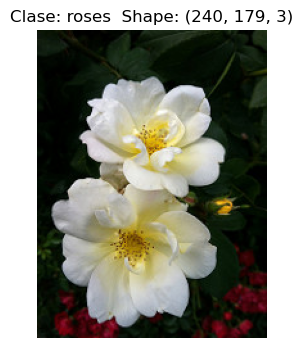

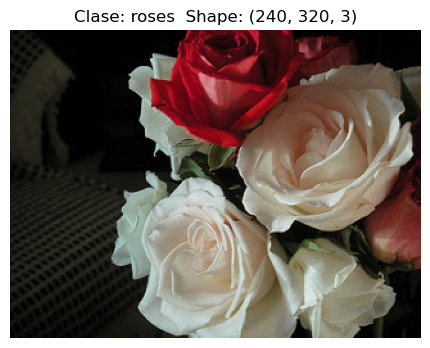

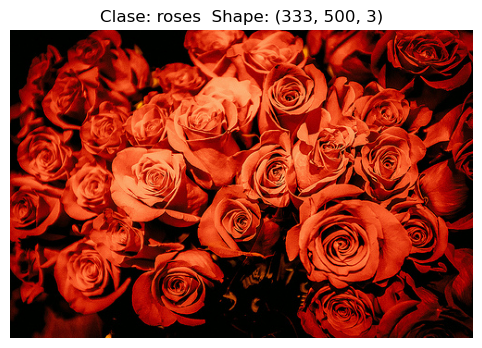

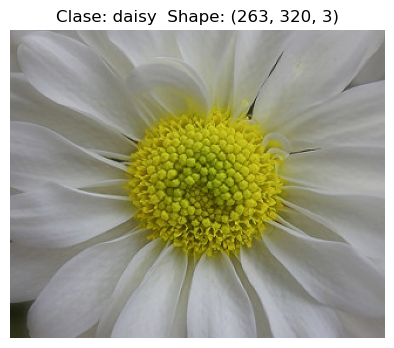

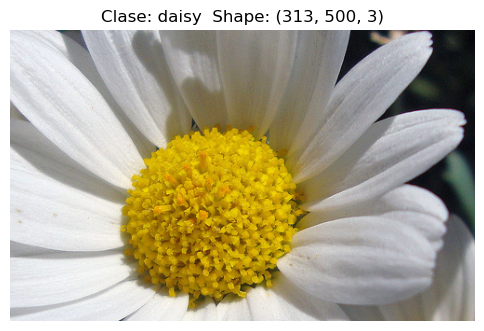

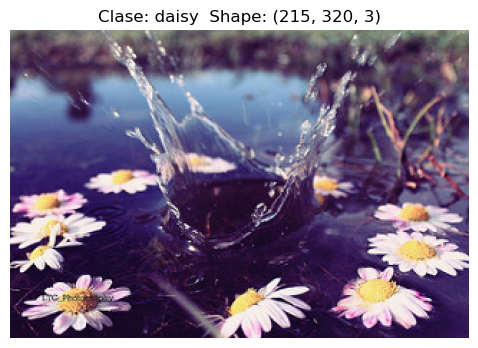

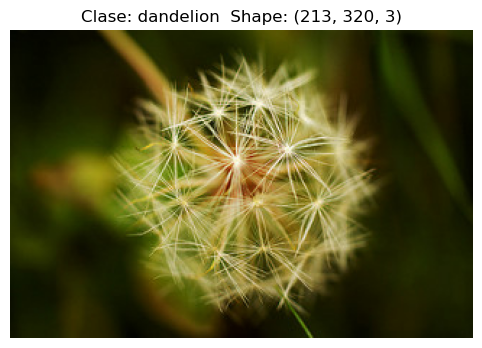

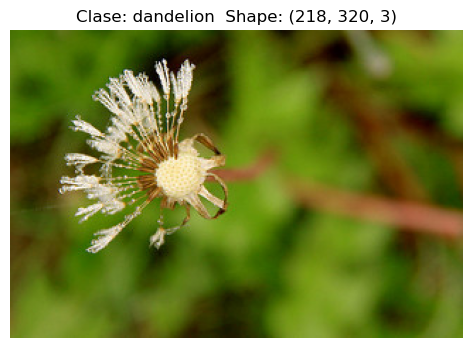

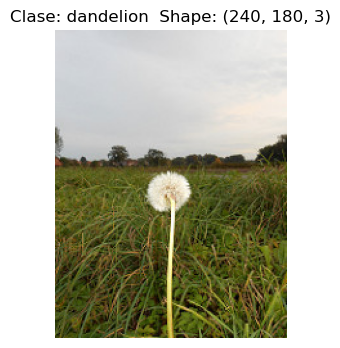

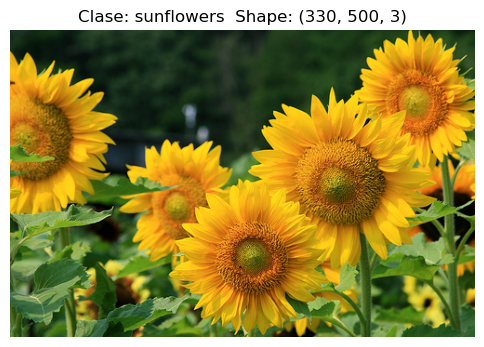

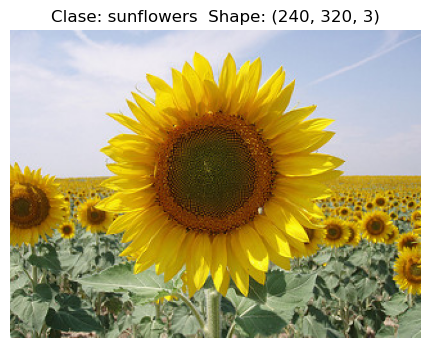

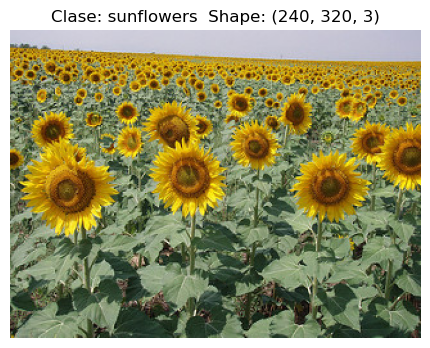

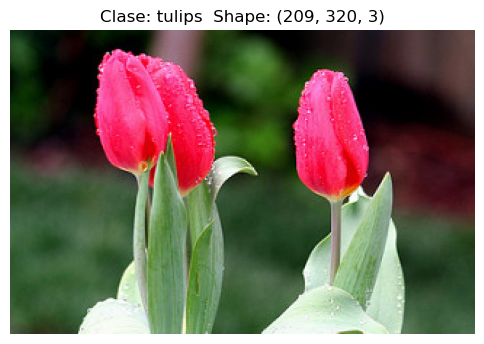

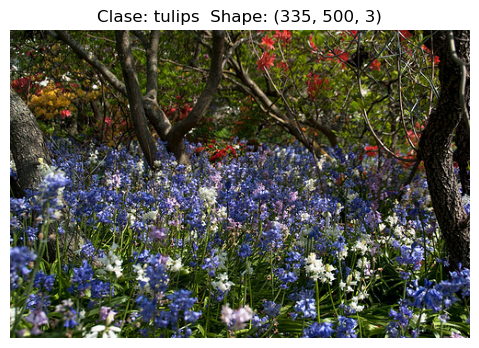

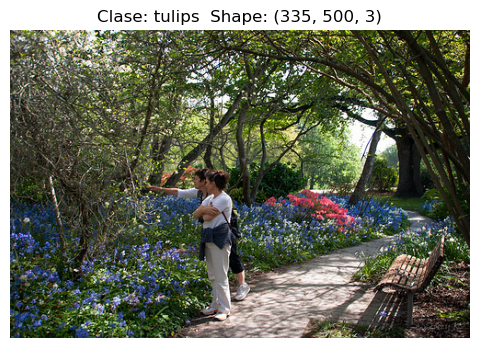

In [14]:
import matplotlib.pyplot as plt      
import matplotlib.image as mpimg       

for clase in classes:
    ruta_clase = os.path.join(train_dir, clase)
    imagenes_clase = os.listdir(ruta_clase)
    
    for i in range(3):
        file_path = os.path.join(ruta_clase, imagenes_clase[i])
        
        plt.figure(figsize=(6, 4))
        plt.axis('Off')
        
        img = mpimg.imread(file_path)
        
        plt.title("Clase: " + clase + "  Shape: " + str(img.shape))
        plt.imshow(img)

# c) Modelo 1: CNN básica (objetivo: accuracy_valid > 60%)


Implemente una red convolucional para resolver el problema de clasificación. Para ello se sugiere una CNN con 3 capas convolucionales + pooling con la siguiente estructura:

Bloque de procesamiento de imagen:
1.   32 kernels -> 64 kernels -> 96 kernels
2.   kernels de 3x3.
3.   Stride = 1 y padding = SI.
4.   Función de activación ReLU.
5.   Maxpooling de 2x2 con stride clásico de 2 pixeles.
6.   Igualamos el tamaño de todas las imágenes a 150 x 150.

Bloque de decisión:
7.   Capa densa de 512 neuronas.
8.   Capa densa de salida.

**Tarea 4: Define un modelo con la estructura anterior**



In [15]:
model = keras.models.Sequential([

    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(150, 150, 3)),
    keras.layers.MaxPooling2D(2, 2),

    
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(2, 2),

    
    keras.layers.Conv2D(96, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(2, 2),

    
    keras.layers.Flatten(),
    
  
    keras.layers.Dense(512, activation='relu'),
    
    keras.layers.Dense(5, activation='softmax')
])

**Tarea 5: Indica el shape de la imagen antes y después de cada capa de la red. Explica cómo has obtenido dichos valores**

| Capa | Shape a la salida | #parámetros |
| :--- | :---: | :---: |
| Conv_1 | (150, 150, 32) | 896 |
| Pool_1 | (75, 75, 32) | 0 |
| Conv_2 | (75, 75, 64) | 18496 |
| Pool_2 | (37, 37, 64) | 0 |
| Conv_3 | (37, 37, 96) | 55392 |
| Pool_3 | (18, 18, 96) | 0 |
| flatten | (31104) | 0 |
| densa_1 | (512) | 15925760 |

**Para calcular el shape:**
* **Para las capas convolucionales:** Como tienen el padding activado con `padding='same'`, el tamaño de la imagen lo calculamos con la fórmula: 
  $$\text{Salida} = \frac{\text{Entrada} - \text{Kernel} + (2 \times \text{Padding})}{\text{Stride}} + 1$$
  Donde el padding se calcula como: $\text{Padding} = \frac{\text{Kernel} - 1}{2}$.
* **Para las capas de pooling:** se divide el tamaño de la imagen de la capa anterior entre el tamaño del pooling (en nuestro caso 2x2).
* **Para la capa flatten y densa:** El shape de la flatten es el total de números estirados en una fila, y el de la densa es el número de neuronas que hayamos puesto.

---

**Para el número de parámetros:**
* **Para las capas convolucionales:** Usamos la fórmula: 
  $$\text{Parámetros} = [(\text{Ancho Kernel} \times \text{Alto Kernel} \times \text{Número de Canales}) + 1] \times \text{Kernels}$$
* **En las capas pooling:** El número de parámetros es siempre **0**, porque estas capas no aprenden nada, solo encogen la imagen.
* **Para la flatten:** El número de parámetros también es **0**. Como su función es aplanar, lo único que hace es multiplicar el alto por el ancho por los canales de la capa anterior para dejarlo todo en una sola línea de números, pero no tiene que aprender ningún peso.
* **Para la capa densa:** Multiplicamos el número de entradas que le llegan (las neuronas de la capa anterior) por el número de neuronas de la propia capa densa, y le sumamos el bias:
  $$\text{Parámetros} = (\text{Entradas} \times \text{Neuronas de la capa}) + \text{Neuronas de la capa}$$

**Tarea 6: Compara el resultado con un summary() del modelo**


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 96)     │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 31104)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    15,925,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,003,109 (61.05 MB)

 Trainable params: 16,003,109 (61.05 MB)

 Non-trainable params: 0 (0.00 B)

Al ejecutar el comando `model.summary()`, podemos comprobar que todos los valores calculados a mano en la tabla de la Tarea 5 coinciden con los resultados:

- **Shapes de salida:** Se verifica cómo el tamaño espacial de la imagen se reduce a la mitad de forma limpia tras cada capa de MaxPooling, manteniendo el alto y el ancho en las convoluciones.
- **Paso por el Flatten:** Al llegar a la capa `flatten_1`, la rejilla de (18, 18, 96) se aplana multiplicando sus dimensiones (18 x 18 x 96), lo que da como resultado un vector de exactamente 31,104 elementos.
- **Capa Densa y Salida:** Los parámetros de la capa `dense_2` (512 neuronas) se calculan multiplicando las entradas por las neuronas más sus sesgos (31104 x 512) + 512 = 15,925,760). Finalmente, la capa de salida `dense_3` muestra las **5** neuronas correspondientes a nuestras 5 clases de flores.

En conclusión, todos los cálculos de las capas coinciden al 100% y el modelo cuenta con un gran total de 16,003,109 parámetros entrenables listos para empezar a aprender.

**Tarea 7: Entrena el modelo de manera que obtenga un accuracy (sobre el conjunto de validación) > 60%.**

* Utilice el optimizador que considere más adecuado.
*   Recuerda que si no se realiza conversión a One-Hot de la etiqueta a predecir, debes utilizar como función de error `SparseCategoricalCrossentropy` (este es el procedimiento que hemos usado en clase).
*   Considera un learning rate en el entorno de 0.001.
*   En el caso de los generators utiliza `class_mode='sparse'`.
*   Puedes utilizar p.e. un `batch_size = 100`.

In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)


train_generator = train_datagen.flow_from_directory(
        train_dir,
        target_size=(150, 150),
        batch_size=100,
        class_mode='sparse')

validation_generator = val_datagen.flow_from_directory(
        val_dir,                
        target_size=(150, 150),
        batch_size=100,      
        class_mode='sparse')  


model.compile(
    loss=tf.keras.losses.sparse_categorical_crossentropy,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
    metrics=['accuracy']
)


es_callback = keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)


history = model.fit(
      train_generator,
      epochs=30, 
      validation_data=validation_generator,
      callbacks=[es_callback],
      verbose=1) 

Found 2935 images belonging to 5 classes.
Found 735 images belonging to 5 classes.
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 124s 4s/step - accuracy: 0.3295 - loss: 1.6339 - val_accuracy: 0.5252 - val_loss: 1.1675
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.5554 - loss: 1.0767 - val_accuracy: 0.5415 - val_loss: 1.1120
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.6395 - loss: 0.9227 - val_accuracy: 0.5891 - val_loss: 1.0428
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 55s 2s/step - accuracy: 0.6845 - loss: 0.8181 - val_accuracy: 0.6190 - val_loss: 0.9903
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.7520 - loss: 0.6624 - val_accuracy: 0.6218 - val_loss: 1.0018
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.8150 - loss: 0.5087 - val_accuracy: 0.6204 - val_loss: 1.0625
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 54s 2s/step - accuracy: 0.8763 - loss: 0.3369 - val_accuracy: 0.6027 - val_loss: 1.3506
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━

**Tarea 8: Muestra la evolución de la función de error (train y valid) durante el entrenamiento.Explica que problema presenta el modelo que hemos entrenado.**

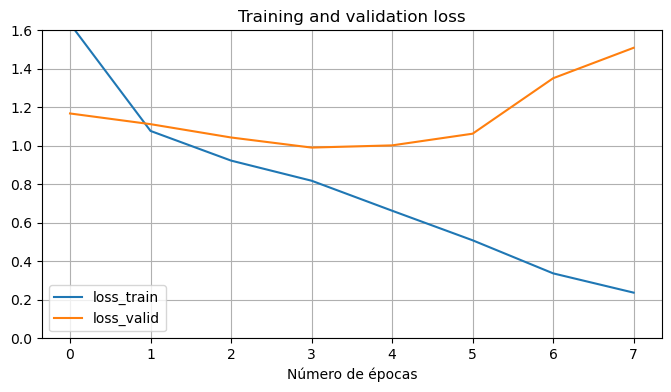

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame({'loss_train': history.history['loss'],
              'loss_valid': history.history['val_loss']}).plot(figsize=(8,4))

plt.grid(True)
plt.ylim(0, 1.6)
plt.xlabel('Número de épocas')
plt.title('Training and validation loss')
plt.show()

El modelo presenta un problema evidente de sobreajuste. Como se puede observar claramente en la gráfica, a partir de la época 3, la curva del error de validación deja de disminuir y empieza a subir notablemente hasta alcanzar un valor cercano a 1.5. Mientras tanto, el error de entrenamiento continúa bajando de forma drástica y continua.

Esto significa que el modelo ha dejado de aprender patrones generales sobre las flores y ha empezado a memorizar los detalles específicos de las imágenes del conjunto de entrenamiento. Al perder su capacidad de generalización, comete cada vez más fallos cuando se le presentan las imágenes nuevas de validación.

Por esta razón, el mecanismo de EarlyStopping actuó de forma correcta deteniendo el proceso en la época 7 tras 4 épocas seguidas sin mejorar el error de validación para evitar que el sobreajuste fuera a más, restaurando automáticamente los mejores pesos del modelo correspondientes a la época 3.

# d) Modelo 2: reducción del overfitting (objetivo: accuracy_valid > 70%)

Para mejorar el accuracy del modelo, vamos a incorporar las dos técnicas más habituales de reducción del overfitting:

    * drop-out
    * data augmentation
    

**Tarea 9: Explica en que consisten y qué utilidad tienen para nuestro problema**





#### 1. Drop-out
Es una técnica que consiste en desactivar aleatoriamente un porcentaje de neuronas de una capa en cada paso del entrenamiento. Al apagar neuronas al azar, obligamos a la red neuronal a no depender de ninguna conexión o neurona específica para reconocer una flor. Esto impide que el modelo memorice detalles muy concretos de una sola imagen de entrenamiento y le fuerza a aprender características mucho más robustas y generales que compartan todas las flores de esa categoría.

#### 2. Data Augmentation
Consiste en generar imágenes de entrenamiento nuevas a partir de las que ya tenemos, aplicándoles transformaciones aleatorias en tiempo de ejecución (como rotaciones, zooms, giros horizontales, recortes o cambios de brillo). Nuestro dataset de flores es relativamente pequeño, lo que facilita que el modelo se lo aprenda de memoria. Al usar Data Augmentation, simula que tenemos un conjunto de datos mucho más grande y variado, enseñando a la red que una rosa sigue siendo una rosa sin importar el ángulo o la posición en la que esté tomada la foto.

**Tarea 10: Construye un nuevo modelo 2 incorporando (en el modelo 1 anterior) el dropout adecuado**

In [19]:
model2 = keras.models.Sequential([
    
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(150, 150, 3)),
    keras.layers.MaxPooling2D(2, 2),
    
   
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(2, 2),
    
    
    keras.layers.Conv2D(96, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(2, 2),
    
    
    keras.layers.Flatten(),
    
    
    keras.layers.Dropout(0.5),
    
   
    keras.layers.Dense(512, activation='relu'),
    
    
    keras.layers.Dense(5, activation='softmax')
])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 96)     │        55,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 18, 18, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 31104)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 31104)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    15,925,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,003,109 (61.05 MB)

 Trainable params: 16,003,109 (61.05 MB)

 Non-trainable params: 0 (0.00 B)

**Tarea 11: Explica que tipos de augmentation vas a considerar y que utilidad tienen en nuestro problema de clasificacion**

1. **Rotación aleatoria:** Gira las fotos de las flores de forma aleatoria. Como en la naturaleza las flores pueden crecer inclinadas o las fotos tomarse desde distintos ángulos, esto enseña a la red a reconocer la flor sin importar su orientación.

2. **Zoom aleatorio:** Acerca o aleja la imagen aleatoriamente. Nos sirve para que el modelo aprenda a identificar los rasgos de la flor tanto si la foto está tomada desde muy cerca como si está capturada desde más lejos.

3. **Volteo horizontal:** Invierte la foto de izquierda a derecha. Una flor sigue siendo exactamente igual sin importar hacia qué lado esté mirando.

**Tarea 12: Entrena el modelo de manera que obtenga un accuracy (sobre el conjunto de validación) > 70%.**

In [20]:
from tensorflow.keras.callbacks import EarlyStopping

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,   
    zoom_range=0.2,      
    horizontal_flip=True, 
    fill_mode='nearest'  
)


val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=100,
    class_mode='sparse'
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(150, 150),
    batch_size=100,
    class_mode='sparse'
)


model2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)


history2 = model2.fit(
    train_generator,
    epochs=30,
    validation_data=validation_generator,
    callbacks=[early_stopping]
)

Found 2935 images belonging to 5 classes.
Found 735 images belonging to 5 classes.
Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 100s 3s/step - accuracy: 0.3315 - loss: 1.5641 - val_accuracy: 0.4639 - val_loss: 1.2647
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.4978 - loss: 1.1669 - val_accuracy: 0.5796 - val_loss: 1.0625
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 85s 3s/step - accuracy: 0.5874 - loss: 1.0466 - val_accuracy: 0.6136 - val_loss: 1.0271
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 86s 3s/step - accuracy: 0.5956 - loss: 1.0119 - val_accuracy: 0.6367 - val_loss: 0.9628
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.6313 - loss: 0.9185 - val_accuracy: 0.6803 - val_loss: 0.8715
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 149s 3s/step - accuracy: 0.6552 - loss: 0.8653 - val_accuracy: 0.6966 - val_loss: 0.8018
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 98s 3s/step - accuracy: 0.6825 - loss: 0.8297 - val_accuracy: 0.7020 - val_loss: 0.7914
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━

**Tarea 13: Muestra la evolucion de la funcion de error durante el entrenamiento. Explica qué diferencias de comportamiento hay entre las gráficas del modelo 1 y el modelo 2**

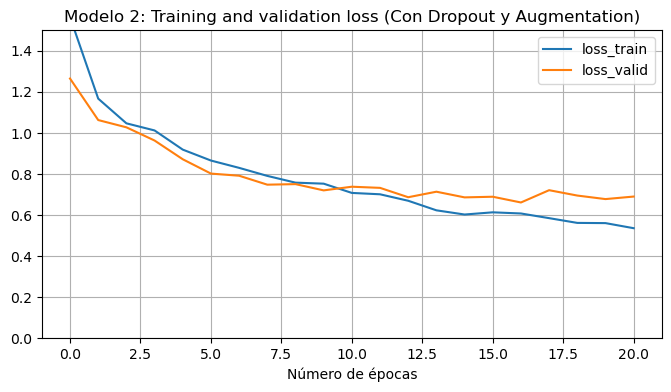

In [21]:
pd.DataFrame({'loss_train': history2.history['loss'],
              'loss_valid': history2.history['val_loss']}).plot(figsize=(8,4))

plt.grid(True)
plt.ylim(0, 1.5)
plt.xlabel('Número de épocas')
plt.title('Modelo 2: Training and validation loss (Con Dropout y Augmentation)')
plt.show()

# c) Modelo 3: Transfer Learning (objetivo: accuracy_valid > 88%)

En nuestro problema de clasificación de flores, el utilizar CNNs diseñadas y entrenadas por nosotros mismos, aparece una barrera en las proximidades del 75-77% de precisión del modelo (siempre sobre validación).

Para superar este escollo, el siguiente paso natural es la utilización de modelos preentrenados. Existe una gran variedad de ellos basados en redes CNNs clásicas, donde la principal diferencia es que acumulan más capas que nuestros modelos 1 y 2. Adicionalmente, en estos modelos se han ido incorporando diferentes propuestas para mejorar la arquitectura de la CNN.

En general, utilizando estos modelos convolucionales preentrenados podemos alcanzar accuracies próximos al 90%. Normalmente, estos modelos han sido previamente entrenados sobre datasets de gran tamaño y con gran número de categorías. P.e. en subconjuntos de Imagenet (14 millones de imagenes de 22K categorías).

Dado que estos modelos se entrenaron para resolver un problema "relativamente" parecido a nuestro problema de clasificación, parece razonable pensar que podemos aprovechar ese conocimiento capturado en la red para resolver nuestro problema de clasificación de flores.



Para elegir el modelo preentrenado que debe utilizar cada grupo, proceda del siguiente modo:
* Paso 1: sume los DNIs de los componentes del grupo (si el grupo tiene un sólo miembro, vaya directamente al paso 2). res = dni_1 + dn_2
* Paso 2: Aplique la siguiente operación al resultado anterior: res mod 6.
* Paso 3: Tome el modelo cuyo número asociado coincide con el resultado de la operación anterior.
* Paso 4: El porcentaje que aparece entre paréntesis junto al nombre del modelo es el accuracy (en validación) que deberías poder alcanzar sin dificultad utilizando el modelo. En todos los casos considera un input_shape = (224, 224, 3).

  0. Resnet50 (>90%)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet50/ResNet50

  1. Resnet101 (>90%) input_shape = (224, 224, 3)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/resnet/ResNet101

  2. VGG16 (>90%) input_shape = (224, 224, 3)
  https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg16/VGG16

  3. VGG19 (>90%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/vgg19/VGG19

  4. Xception (>88%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/xception/Xception

  5. Inceptionv3 (>88%) input_shape = (224, 224, 3) https://www.tensorflow.org/api_docs/python/tf/keras/applications/inception_v3/InceptionV3

P.e. si los DNIs de los alumnos son: 12345678 y 23456781. La suma es 35802459. De donde 35802459 mod 6 = 3. Por tanto, tomaríamos el modelo VGG16.

Recuerda que puedes utilizar el siguiente post como referencia del uso de transfer learning: https://www.learndatasci.com/tutorials/hands-on-transfer-learning-keras/

**Tarea 14: Importa el modelo desde Tensorflow**

Dado que este modelo ha sido entrenado para clasificar entre 1.000 categorías, las capas densas finales del modelo no son útiles para nuestro problema de clasificación de 5 categorías (es lo que suele llamarse include_top = SI/NO). De manera que eliminamos lo que a veces se suele llamar el "top model". De este modo sólo nos quedamos con la parte que hace la funcionalidad de "procesamiento" de la imagen.

In [22]:
from tensorflow.keras.applications.inception_v3 import InceptionV3

base_model = InceptionV3(
    weights='imagenet', 
    include_top=False, 
    input_shape=(224, 224, 3)
)

**Tarea 15: Personalizar el bloque de decisión**  
Añadimos una capa de flatten y tres nuevas capas densas especificas para nuestro problema con dimensiones 4096, 1072 y la que necesite la capa de salida (con sus correspondientes drop-outs).

In [23]:
model3 = keras.models.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    
    keras.layers.Dense(4096, activation='relu'),
    keras.layers.Dropout(0.5),
    
    keras.layers.Dense(1072, activation='relu'),
    keras.layers.Dropout(0.5),
    
    keras.layers.Dense(5, activation='softmax')
])

model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │     8,392,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1072)           │     4,391,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │         5,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,592,837 (131.96 MB)

 Trainable params: 34,558,405 (131.83 MB)

 Non-trainable params: 34,432 (134.50 KB)

**Tarea 16: Congelar los pesos que no se vayan a entrenar**

Previo a hacer el denominado `Fine-Tuning` del modelo, indicaremos a Tensorflow que únicamente debe entrenar:

   * Las dos últimas capas convolucionales de la red preentrenada, de las que realizaremos un ajuste fino de los pesos.
   * Las tres capas densas que hemos incluido nuevas.

In [24]:
base_model.trainable = True

total_capas_base = len(base_model.layers)


for layer in base_model.layers[:-2]:
    layer.trainable = False


model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inception_v3 (Functional)       │ (None, 5, 5, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │     8,392,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1072)           │     4,391,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │         5,365 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,592,837 (131.96 MB)

 Trainable params: 12,790,053 (48.79 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

**Tarea 17: Crear los datagenerators oportunos**

Para ello:
> * Utiliza Data augmentation.  
> * Las imágenes tienen que ser preprocesadas igual que cuando se entrenó el modelo pre.entrenado original. Para ello se utiliza el parámetro `preprocessing_function=preprocess_input` (preprocess_input importado desde `keras.applications.xxxxxx` en ambos generators (train y valid). Por tanto, no hay que indicarle `rescale`. En caso de ser necesario, se encargará `preprocess_input`.  
> * Dado que estamos reutilizando un modelo que no "es nuestro", deberemos ceñirnos al tamaño de imagen que permite la red a la entrada. Recuerda que debe ser: 224x224.

In [25]:
from tensorflow.keras.applications.inception_v3 import preprocess_input

train_datagen_pre = ImageDataGenerator(
    preprocessing_function=preprocess_input, 
    rotation_range=40,    
    zoom_range=0.2,     
    horizontal_flip=True,
    fill_mode='nearest'
)


val_datagen_pre = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


train_generator_model3 = train_datagen_pre.flow_from_directory(
    train_dir,
    target_size=(224, 224), 
    batch_size=100,
    class_mode='sparse'
)

validation_generator_model3 = val_datagen_pre.flow_from_directory(
    val_dir,
    target_size=(224, 224), 
    batch_size=16,
    class_mode='sparse'
)

Found 2935 images belonging to 5 classes.
Found 735 images belonging to 5 classes.


**Tarea 18: Haz el fine-tuning del modelo con el objetivo de alcanzar un accuracy (sobre el conjunto de validación > 88%).**

A la hora de entrenar un modelo pretrained es típico bajar el learning rate respecto al que utilizaríamos para un modelo nuestro desde cero.

In [26]:
from tensorflow.keras.optimizers import Adam

optimizador_suave = Adam(learning_rate=0.0001)


model3.compile(
    optimizer=optimizador_suave,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)


early_stopping_pre = EarlyStopping(
    monitor='val_loss',
    patience=4,  
    restore_best_weights=True 
)


history3 = model3.fit(
    train_generator_model3,
    epochs=25,            
    validation_data=validation_generator_model3,
    callbacks=[early_stopping_pre]
)

Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 291s 9s/step - accuracy: 0.6164 - loss: 1.0077 - val_accuracy: 0.7946 - val_loss: 0.5429
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 296s 10s/step - accuracy: 0.7724 - loss: 0.6123 - val_accuracy: 0.8218 - val_loss: 0.4907
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 257s 9s/step - accuracy: 0.8068 - loss: 0.5366 - val_accuracy: 0.8367 - val_loss: 0.4551
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 257s 9s/step - accuracy: 0.8303 - loss: 0.4786 - val_accuracy: 0.8435 - val_loss: 0.4463
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 223s 7s/step - accuracy: 0.8395 - loss: 0.4529 - val_accuracy: 0.8422 - val_loss: 0.4353
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 221s 7s/step - accuracy: 0.8440 - loss: 0.4362 - val_accuracy: 0.8558 - val_loss: 0.4198
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 226s 8s/step - accuracy: 0.8610 - loss: 0.3876 - val_accuracy: 0.8558 - val_loss: 0.4157
Epoch 8/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 201s 7s/step - accuracy: 0.8528 - loss: 0.3983 - val_accuracy: 0.8639 - 